# Lab: Relationships Between Categorical Features

Imagine James Cameron has hired you to develop two character profiles for a Titanic movie reboot: one “most likely to survive” and one “least likely to survive.” Support both profiles with passenger data and visualizations, then connect them to real people and their biographies.

These labels describe profiles suggested by observed group survival percentages in this dataset. They are not guaranteed individual outcomes, a validated prediction model, or proof that any feature caused survival.


## Learning goals

- Apply the six-step analysis workflow to categorical comparisons.
- Justify categories created from age and travel-companion counts.
- Distinguish raw counts from survival percentages within groups.
- Build clearly labeled figures and check their meaning.
- Support character profiles with evidence and identify matching passengers.
- Connect data records to cited historical biographies.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context? Do the original values support the coding and interpretation?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Use one six-step workflow for the complete character-profile investigation. All six feature comparisons belong together in Step 3: Evidence.


## Dataset and scope

Use the supplied `data/titanic_passengers.csv`, the 891-row training dataset from [Kaggle Titanic: Machine Learning from Disaster](https://www.kaggle.com/c/titanic/data). Each row represents a passenger in this file; it is not a complete passenger-and-crew list. Consult the source dictionary when interpreting the features.

Analyze only categorical comparisons with `Survived`. Use `Pclass` instead of `Fare`; do not analyze fare. Age is the exception: convert it to justified categories before comparing survival. Treat travel-companion counts as categories, combining sparse groups if appropriate. Use names and passenger IDs only to identify people.

| Feature | Meaning and role |
| --- | --- |
| `Survived` | Categorical outcome: 0 = did not survive, 1 = survived |
| `Pclass` | Ordered passenger class: 1, 2, or 3; categorical despite numeric storage |
| `Sex` | Recorded sex category |
| `Age` | Age in years; use only through your chosen age groups |
| `Parch` | Count of parents/children aboard; use as categories or collapse into groups |
| `SibSp` | Count of siblings/spouse aboard; use as categories or collapse into groups |
| `Embarked` | Embarkation port: C = Cherbourg, Q = Queenstown, S = Southampton |
| `Name`, `PassengerId` | Passenger identification for matching records to biographies |

The file also contains `Ticket`, `Fare`, and `Cabin`; do not use them as comparison features in this lab.


## Using AI tools responsibly

You may use AI for questions, debugging, or feedback. You remain responsible for understanding the code and checking claims against the output. Read the actual Encyclopedia Titanica biographies rather than using an uncited AI-generated fact. Disclose AI use in the final reflection.


## Step 1: Question

**Which categorical characteristics support a “most likely to survive” profile and a “least likely to survive” profile in this Titanic dataset?**

Consider age group, sex, passenger class, parents/children aboard, siblings/spouse aboard, and embarkation port together as parts of this one investigation.


**Before examining survival percentages, describe your predicted high-survival and low-survival profiles. What reasoning or prior knowledge supports your predictions?**

Your answer:
I predict that the high-survival profile will be a female passenger, younger in age, traveling in first class, and possibly traveling with a small number of family members. I expect the low-survival profile to be an adult male traveling in third class, possibly alone or with a larger family group. My prediction is based on prior knowledge of the Titanic evacuation, where women and children were generally prioritized for lifeboats and wealthier passengers may have had better access to the upper decks.

## Step 2: Data


## Load and inspect the data

Use `titanic_df` as the DataFrame name. Keep the original columns so your category choices can be checked.


In [1]:
# Import pandas as pd and matplotlib.pyplot as plt.
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Read data/titanic_passengers.csv into titanic_df.
titanic_df = pd.read_csv("data/titanic_passengers.csv")

In [3]:
# Display the first five rows.
titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
# Display .info().
titanic_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [5]:
# Display the missing-value count for each feature.
titanic_df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

**What does one row represent? Which feature is the target, and what do its codes mean?**

Your answer:
Each row represents one passenger in the Titanic dataset. The target feature is Survived. A value of 0 means the passenger did not survive, while a value of 1 means the passenger survived.

Complete this table from the inspection. Distinguish a feature's meaning from its Pandas storage type; numeric codes can represent categories.


| Feature | Data type (categorical/quantitative/identifier) | Data storage type | Missing values |
| --- | --- | --- | ---: |
| `PassengerId` | identifier | int64 | 0 |
| `Name` | identifier | str | 0 |
| `Survived` | categorical | int64 | 0 |
| `Pclass` | categorical | int64 | 0 |
| `Sex` | categorical | str | 0 |
| `Age` | quantitative | float64 | 177 |
| `Parch` | quantitative count; analyzed as categories | int64 | 0 |
| `SibSp` | quantitative count; analyzed as categories | int64 | 0 |
| `Embarked` | categorical | str | 2 |

Storage types reflect the verification environment; older Pandas versions may show `object` instead of `str` for text.

## Plan your age groups before comparing survival

Choose your own age categories. You might use children versus adults, split at 16, 18, or 20, or define several groups such as children, teens, young adults, and older adults. There is no single required cutoff. Give a reasoned argument based on the meaning of the groups and their usefulness, not just which split produces the strongest survival difference.

Write exact boundaries, including where an age exactly at a cutoff belongs. Cover all known ages without overlapping groups. Preserve unknown ages as missing or label them “Unknown”; do not accidentally classify them as adults. If you exclude unknown ages from this comparison, state that denominator choice. Do not guess an age from whether someone survived.


| Age-group label | Exact rule (including boundary values) | Reason for this choice |
| --- | --- | --- |
| Child | Known age <= 12 | Separate young children |
| Teen | 12 < age <= 17 | Separate adolescents |
| Young Adult | 17 < age <= 34 | Early adulthood |
| Adult | 34 < age <= 54 | Middle adulthood |
| Older Adult | Known age > 54 | Older passengers |
| Unknown | Age is missing | Preserve missingness without guessing |

These are descriptive choices, not universal age definitions. All observed ages are positive.

**Why are your age groups reasonable? How will you handle unknown ages, and why?**

Your answer:

These groups separate children, teenagers, and stages of adulthood while retaining the original age column. The right endpoints are included, so ages 12, 17, 34, and 54 belong to Child, Teen, Young Adult, and Adult respectively. Unknown ages stay in a separate category and remain in the overall dataset. Their survival percentage describes missing-age records, not a biological age group.

Create `age_group` using `.loc` or `pd.cut`. If using `.loc`, initialize the column to an explicit “Unknown” label and assign labels only where ages satisfy your rules. If using `pd.cut`, choose its interval boundaries carefully and document whether intervals include their right or left endpoint. Count the observations in each category, including unknowns.


In [6]:
# Create age_group and display its category counts, including unknown ages.
titanic_df["age_group"] = pd.cut(
    titanic_df["Age"],
    bins=[-float("inf"), 12, 17, 34, 54, float("inf")],
    labels=["Child", "Teen", "Young Adult", "Adult", "Older Adult"]
)
# Preserve missing ages as their own category.
titanic_df["age_group"] = titanic_df["age_group"].cat.add_categories("Unknown")
titanic_df["age_group"] = titanic_df["age_group"].fillna("Unknown")

# Display the number of passengers in each age group.
titanic_df["age_group"].value_counts(dropna=False)

age_group
Young Adult    365
Adult          194
Unknown        177
Child           69
Teen            44
Older Adult     42
Name: count, dtype: int64

**Are any age groups very small? Would a different grouping be more useful? Explain any revision before comparing survival.**

Your answer:
The Teen and Older Adult groups are the smallest, with 44 and 42 passengers, but they still contain enough observations to compare with the other groups. I will keep the current age categories because they represent meaningful age ranges and were chosen before examining survival outcomes. The 177 passengers with missing ages will remain in the Unknown category rather than being assigned to an age group without evidence.

### Choose travel-companion categories

Inspect the frequencies of `Parch` and `SibSp`. Treat their values as discrete categories or collapse them into meaningful groups, such as none/any or none/one/two or more. Explain your choices, particularly when some categories have few passengers. Preserve the original columns.


In [7]:
# Display Parch and SibSp category counts; create any grouped features and display their counts.
print("Parch counts:")
print(titanic_df["Parch"].value_counts().sort_index())

print()

# Display the frequency of each SibSp category.
print("SibSp counts:")
print(titanic_df["SibSp"].value_counts().sort_index())

Parch counts:
Parch
0    678
1    118
2     80
3      5
4      4
5      5
6      1
Name: count, dtype: int64

SibSp counts:
SibSp
0    608
1    209
2     28
3     16
4     18
5      5
8      7
Name: count, dtype: int64


In [8]:
# Group Parch into none, one, or two-or-more categories.
titanic_df["parch_group"] = "Two or more"
titanic_df.loc[titanic_df["Parch"] == 0, "parch_group"] = "None"
titanic_df.loc[titanic_df["Parch"] == 1, "parch_group"] = "One"

# Group SibSp into none, one, or two-or-more categories.
titanic_df["sibsp_group"] = "Two or more"
titanic_df.loc[titanic_df["SibSp"] == 0, "sibsp_group"] = "None"
titanic_df.loc[titanic_df["SibSp"] == 1, "sibsp_group"] = "One"

# Display the grouped counts.
print("Parch grouped counts:")
print(titanic_df["parch_group"].value_counts())

print()

print("SibSp grouped counts:")
print(titanic_df["sibsp_group"].value_counts())

Parch grouped counts:
parch_group
None           678
One            118
Two or more     95
Name: count, dtype: int64

SibSp grouped counts:
sibsp_group
None           608
One            209
Two or more     74
Name: count, dtype: int64


**What travel-companion groups will you use, and why? State any exclusions and how you will handle unknown embarkation ports. Which observations form the denominator for each comparison?**

Your answer:
I will group both Parch and SibSp into None, One, and Two or more. I chose these groups because some of the original higher-number categories contain very few passengers, which could make their survival percentages misleading. No passengers are missing Parch or SibSp values, so all 891 passengers can be used for those comparisons. For Embarked, the two passengers with missing embarkation ports will be excluded from that comparison rather than assigned to a port without evidence. The denominator for each survival percentage will be all passengers in that particular comparison category, including both survivors and non-survivors.

## Step 3: Evidence

Bring all six feature comparisons together here. For each feature:

- Display a count cross-tab with comparison categories in rows and survival outcomes in columns.
- Calculate survival percentages within each comparison group and display only the percentage who survived (column `1`). Keep group counts available for context.
- Make a bar chart of the conditional percentage who survived, with a meaningful title, descriptive axes, readable category labels, and named colors. Use a 0–100 percentage scale and `plt.legend()` if a legend is needed. Move it outside the axes if it covers the data.

Use separate code cells for the individual operations and add cells as needed. The subsections below organize the evidence; they are not separate workflows.


### Age groups

Compare `age_group` with `Survived` using your Data-step choices.


In [9]:
# Create and display the count cross-tab.
age_counts = pd.crosstab(
    titanic_df["age_group"],
    titanic_df["Survived"]
)

# Display the count table.
age_counts

Survived,0,1
age_group,,
Child,29,40
Teen,23,21
Young Adult,230,135
Adult,113,81
Older Adult,29,13
Unknown,125,52


In [10]:
# Calculate conditional percentages and display only the survived column.
age_percentages = pd.crosstab(
    titanic_df["age_group"],
    titanic_df["Survived"],
    normalize="index"
) * 100

# Display only the percentage who survived.
age_survived_pct = age_percentages[1]
age_survived_pct

age_group
Child          57.971014
Teen           47.727273
Young Adult    36.986301
Adult          41.752577
Older Adult    30.952381
Unknown        29.378531
Name: 1, dtype: float64

For age groups, also display joint percentages (`normalize="all"`, multiplied by 100) and make a count chart showing both outcomes. Compare this with the survivor-percentage chart to distinguish counts, joint percentages, and within-group percentages.


In [11]:
# Display joint percentages, then create a count chart in a separate cell.
age_joint_percentages = pd.crosstab(
    titanic_df["age_group"],
    titanic_df["Survived"],
    normalize="all"
) * 100

# Display the joint percentages.
age_joint_percentages

Survived,0,1
age_group,,
Child,3.254770,4.489338
Teen,2.581369,2.356902
Young Adult,25.813692,15.151515
Adult,12.682379,9.090909
Older Adult,3.254770,1.459035
Unknown,14.029181,5.836139


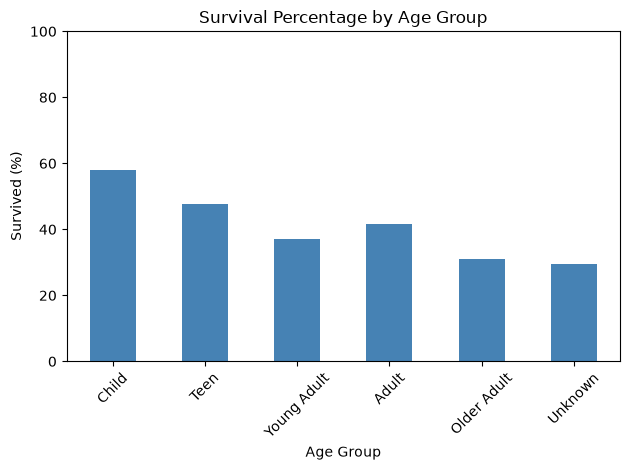

In [12]:
# Plot the conditional percentage who survived.
age_survived_pct.plot(
    kind="bar",
    color="steelblue"
)

plt.title("Survival Percentage by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survived (%)")
plt.ylim(0, 100)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

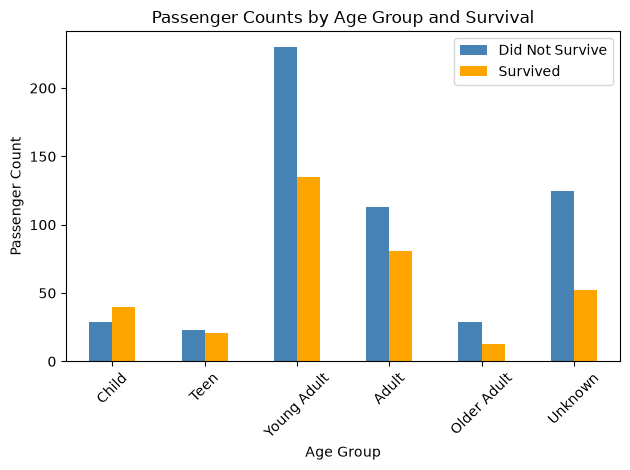

In [13]:
# Plot raw passenger counts for both survival outcomes.
age_counts.plot(
    kind="bar",
    color=["steelblue", "orange"]
)

plt.title("Passenger Counts by Age Group and Survival")
plt.xlabel("Age Group")
plt.ylabel("Passenger Count")
plt.legend(["Did Not Survive", "Survived"])
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Sex

Compare `Sex` with `Survived` using your Data-step choices.


In [14]:
# Create and display the count cross-tab.
sex_counts = pd.crosstab(
    titanic_df["Sex"],
    titanic_df["Survived"]
)

sex_counts

Survived,0,1
Sex,,
female,81,233
male,468,109


In [15]:
# Calculate conditional percentages and display only the survived column.
sex_percentages = pd.crosstab(
    titanic_df["Sex"],
    titanic_df["Survived"],
    normalize="index"
) * 100

# Display only the percentage who survived.
sex_survived_pct = sex_percentages[1]
sex_survived_pct

Sex
female    74.203822
male      18.890815
Name: 1, dtype: float64

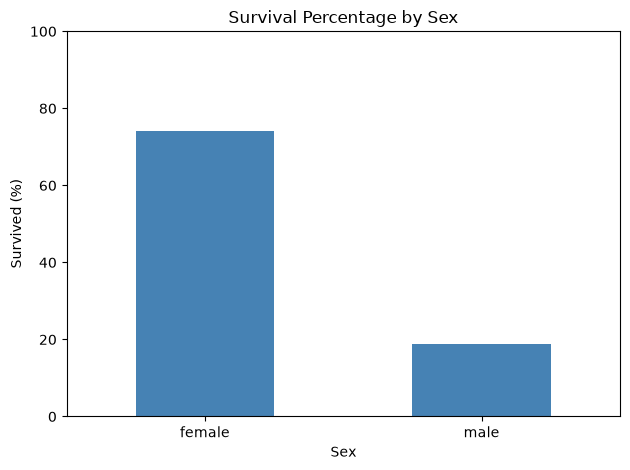

In [16]:
# Plot the conditional percentage who survived.
sex_survived_pct.plot(
    kind="bar",
    color="steelblue"
)

plt.title("Survival Percentage by Sex")
plt.xlabel("Sex")
plt.ylabel("Survived (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Passenger class

Compare `Pclass` with `Survived` using your Data-step choices.


In [17]:
# Create and display the count cross-tab.
pclass_counts = pd.crosstab(
    titanic_df["Pclass"],
    titanic_df["Survived"]
)

pclass_counts

Survived,0,1
Pclass,,
1,80,136
2,97,87
3,372,119


In [18]:
# Calculate conditional percentages and display only the survived column.
pclass_percentages = pd.crosstab(
    titanic_df["Pclass"],
    titanic_df["Survived"],
    normalize="index"
) * 100

# Display only the percentage who survived.
pclass_survived_pct = pclass_percentages[1]
pclass_survived_pct

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: 1, dtype: float64

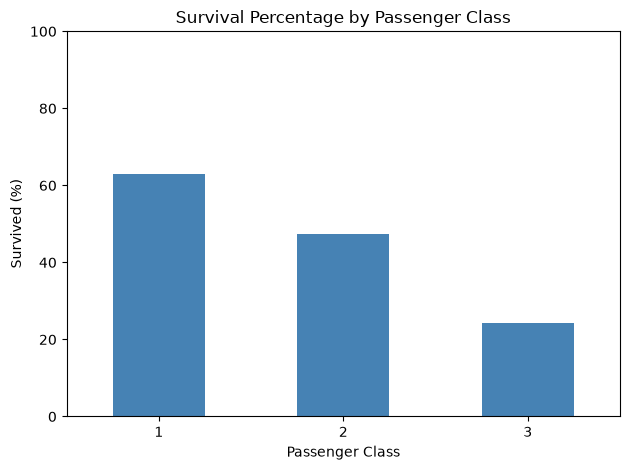

In [19]:
# Plot the conditional percentage who survived.
pclass_survived_pct.plot(
    kind="bar",
    color="steelblue"
)

plt.title("Survival Percentage by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survived (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Parents or children aboard

Compare `Parch or your derived group` with `Survived` using your Data-step choices.


In [20]:
# Create and display the count cross-tab.
parch_counts = pd.crosstab(
    titanic_df["parch_group"],
    titanic_df["Survived"]
)

parch_counts

Survived,0,1
parch_group,,
None,445,233
One,53,65
Two or more,51,44


In [21]:
# Calculate conditional percentages and display only the survived column.
parch_percentages = pd.crosstab(
    titanic_df["parch_group"],
    titanic_df["Survived"],
    normalize="index"
) * 100

# Display only the percentage who survived.
parch_survived_pct = parch_percentages[1]
parch_survived_pct

parch_group
None           34.365782
One            55.084746
Two or more    46.315789
Name: 1, dtype: float64

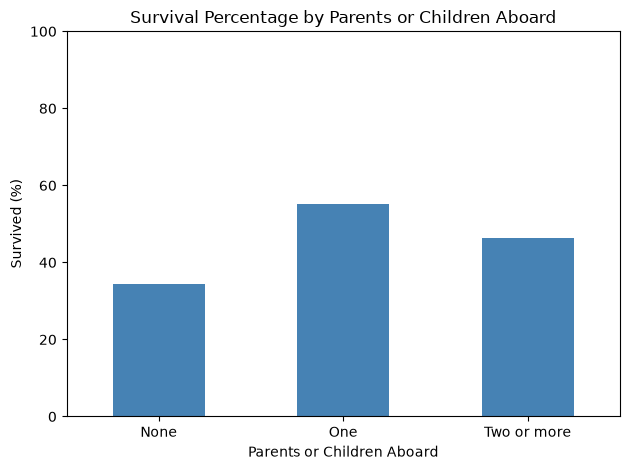

In [22]:
# Plot the conditional percentage who survived.
parch_survived_pct.plot(
    kind="bar",
    color="steelblue"
)

plt.title("Survival Percentage by Parents or Children Aboard")
plt.xlabel("Parents or Children Aboard")
plt.ylabel("Survived (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Siblings or spouse aboard

Compare `SibSp or your derived group` with `Survived` using your Data-step choices.


In [23]:
# Create and display the count cross-tab.
sibsp_counts = pd.crosstab(
    titanic_df["sibsp_group"],
    titanic_df["Survived"]
)

sibsp_counts

Survived,0,1
sibsp_group,,
None,398,210
One,97,112
Two or more,54,20


In [24]:
# Calculate conditional percentages and display only the survived column.
sibsp_percentages = pd.crosstab(
    titanic_df["sibsp_group"],
    titanic_df["Survived"],
    normalize="index"
) * 100

# Display only the percentage who survived.
sibsp_survived_pct = sibsp_percentages[1]
sibsp_survived_pct

sibsp_group
None           34.539474
One            53.588517
Two or more    27.027027
Name: 1, dtype: float64

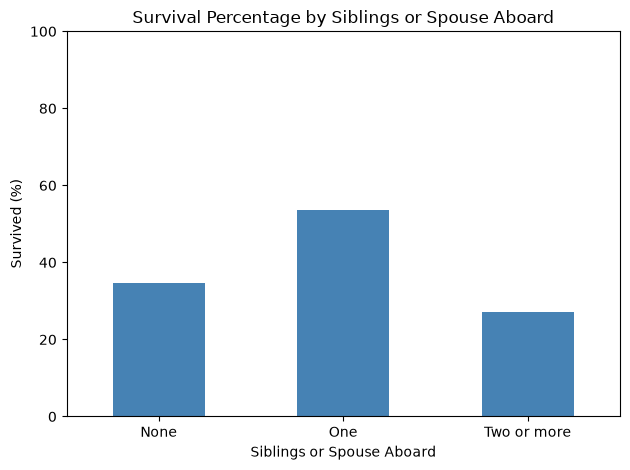

In [25]:
# Plot the conditional percentage who survived.
sibsp_survived_pct.plot(
    kind="bar",
    color="steelblue"
)

plt.title("Survival Percentage by Siblings or Spouse Aboard")
plt.xlabel("Siblings or Spouse Aboard")
plt.ylabel("Survived (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Embarkation port

Compare `Embarked` with `Survived` using your Data-step choices.


In [26]:
# Create and display the count cross-tab.
embarked_counts = pd.crosstab(
    titanic_df["Embarked"],
    titanic_df["Survived"]
)

embarked_counts

Survived,0,1
Embarked,,
C,75,93
Q,47,30
S,427,217


In [27]:
# Calculate conditional percentages and display only the survived column.
embarked_percentages = pd.crosstab(
    titanic_df["Embarked"],
    titanic_df["Survived"],
    normalize="index"
) * 100

# Display only the percentage who survived.
embarked_survived_pct = embarked_percentages[1]
embarked_survived_pct

Embarked
C    55.357143
Q    38.961039
S    33.695652
Name: 1, dtype: float64

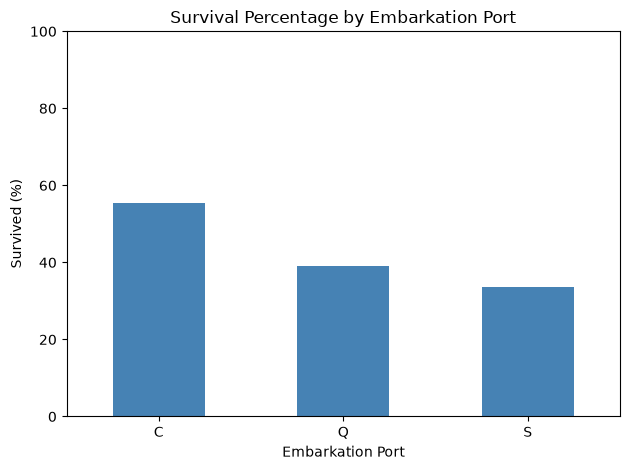

In [28]:
# Plot the conditional percentage who survived.
embarked_survived_pct.plot(
    kind="bar",
    color="steelblue"
)

plt.title("Survival Percentage by Embarkation Port")
plt.xlabel("Embarkation Port")
plt.ylabel("Survived (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Summarize the evidence

Record the highest- and lowest-survival categories for each feature. Include percentages and group sizes; mention ties or very small groups that affect interpretation.


| Feature | Highest-survival category, percentage, and group size | Lowest-survival category, percentage, and group size |
| --- | --- | --- |
| Sex | female: 74.20% survived (233 of 314 passengers) | male: 18.89% survived (109 of 577 passengers) |
| Age groups | Child: 57.97% survived (40 of 69 passengers) | Unknown: 29.38% survived (52 of 177 passengers) |
| Passenger class | 1: 62.96% survived (136 of 216 passengers) | 3: 24.24% survived (119 of 491 passengers) |
| Parents or children aboard | One: 55.08% survived (65 of 118 passengers) | None: 34.37% survived (233 of 678 passengers) |
| Siblings or spouse aboard | One: 53.59% survived (112 of 209 passengers) | Two or more: 27.03% survived (20 of 74 passengers) |
| Embarkation port | C: 55.36% survived (93 of 168 passengers) | S: 33.70% survived (217 of 644 passengers) |

Unknown is the lowest age category overall, but Older Adult is the lowest among known-age groups. Teen (44), Older Adult (42), and Queenstown (77) are relatively small. Two missing embarkation ports are excluded only from that comparison.

**Using the age comparison, interpret one joint percentage and one conditional percentage. What denominator does each use, and which figure answers the survival-likelihood question more clearly?**

Your answer:
For example, surviving children make up about 4.49% of the entire dataset, because the joint percentage uses all 891 passengers as its denominator. In comparison, 57.97% of children survived, where the denominator is only the 69 passengers classified as children. The conditional percentage answers the survival-likelihood question more clearly because it compares survivors with all passengers within the same age group.

The raw-count chart shows more survivors among Young Adults than Children because there are more Young Adults in the file. The conditional-percentage chart instead shows Children with the higher survival rate. Large survivor counts alone do not mean a higher chance of survival.

## Step 4: Check

Check the meaning of your combined evidence, rather than repeating the initial row count or missing-value inspection.

- Compare each age group's minimum and maximum known ages with your declared boundaries, including exact cutoffs and unknown ages.
- If you collapsed travel-companion categories, cross-tab the original counts against your group labels.
- Check that percentages use all passengers in the relevant group, not just survivors. Compare the direction of the percentages with the count tables.
- Identify sparse groups or implausible values that deserve caution.


In [29]:
# Check age-group boundaries and unknown ages.
print(
    titanic_df.groupby(
        "age_group",
        observed=False
    )["Age"].agg(["count", "min", "max"])
)

print()

# Check how many passengers have unknown ages.
print("Unknown ages:", titanic_df["Age"].isna().sum())

             count    min   max
age_group                      
Child           69   0.42  12.0
Teen            44  13.00  17.0
Young Adult    365  18.00  34.0
Adult          194  34.50  54.0
Older Adult     42  55.00  80.0
Unknown          0    NaN   NaN

Unknown ages: 177


In [30]:
# Check travel-companion category mappings if you created grouped features.
# Check how the original Parch values map to our grouped categories.
print("Parch mapping:")
print(
    pd.crosstab(
        titanic_df["Parch"],
        titanic_df["parch_group"]
    )
)

print()

# Check how the original SibSp values map to our grouped categories.
print("SibSp mapping:")
print(
    pd.crosstab(
        titanic_df["SibSp"],
        titanic_df["sibsp_group"]
    )
)

Parch mapping:
parch_group  None  One  Two or more
Parch                              
0             678    0            0
1               0  118            0
2               0    0           80
3               0    0            5
4               0    0            4
5               0    0            5
6               0    0            1

SibSp mapping:
sibsp_group  None  One  Two or more
SibSp                              
0             608    0            0
1               0  209            0
2               0    0           28
3               0    0           16
4               0    0           18
5               0    0            5
8               0    0            7


**Do the age boundaries, category mappings, and denominators match your intentions? What would make you suspicious, and did you find or correct any issues? Which small groups limit interpretation?**

Your answer:
The age boundaries and travel-companion category mappings match my intended definitions. Missing ages remain in the Unknown category rather than being assigned to an age group without evidence. Parch and SibSp values of 0 are classified as None, values of 1 as One, and values of 2 or more as Two or more. The denominator for each survival percentage includes all passengers in that category, not only the survivors. The Embarked comparison excludes the two passengers with missing embarkation ports. I would be suspicious if ages appeared outside their intended boundaries, grouped values were mapped incorrectly, or percentages were calculated using only survivors. I did not find any major mapping problems. The Teen group (44 passengers), Older Adult group (42 passengers), and Queenstown embarkation group (77 passengers) are smaller than several other categories, so their percentages should be interpreted with more caution.

## Step 5: Conclusion

Use the combined evidence to develop the two profiles, find matching passengers, and connect them to historical biographies.


### Build your two character profiles

Combine the evidence into a “most likely to survive” profile and a “least likely to survive” profile. Include all six elements. Cite the relevant group percentage and size for each choice. Do not multiply separate feature percentages to produce an individual survival probability: the features may be related, and separate comparisons do not establish the survival rate for their combination.


| Profile element | Most likely profile: category and evidence | Least likely profile: category and evidence |
| --- | --- | --- |
| Sex | female: 74.20% survived (233 of 314 passengers) | male: 18.89% survived (109 of 577 passengers) |
| Age groups | Child: 57.97% survived (40 of 69 passengers) | Older Adult: 30.95% survived (13 of 42 passengers) |
| Passenger class | 1: 62.96% survived (136 of 216 passengers) | 3: 24.24% survived (119 of 491 passengers) |
| Parents or children aboard | Two or more: 46.32% survived (44 of 95 passengers) | None: 34.37% survived (233 of 678 passengers) |
| Siblings or spouse aboard | One: 53.59% survived (112 of 209 passengers) | None: 34.54% survived (210 of 608 passengers) |
| Embarkation port | S: 33.70% survived (217 of 644 passengers) | S: 33.70% survived (217 of 644 passengers) |

These are the revised profiles that match actual records. The original separate-category maxima/minima remain in the evidence table above. Port codes: S = Southampton, C = Cherbourg, Q = Queenstown.

**Write a short character description for each profile. Explain any tradeoffs where the evidence does not point to a single obvious combination.**

Your answer:

Most-likely profile: female, child, first class, two or more parents/children aboard, one sibling/spouse aboard, embarked at Southampton. Least-likely profile: male, older adult, third class, no parents/children aboard, no siblings/spouse aboard, embarked at Southampton.

The original most-likely choices were One parent/child and Cherbourg; the original least-likely choice was Two or more siblings/spouse. Those complete combinations had no matches. The revised choices preserve all six features and prioritize retaining sex, age, and class. Unknown has the lowest observed age-category rate, but it describes missing information; Older Adult is the lowest known-age group and is a usable character trait. These revisions mean the labels are descriptive starting points, not proven maximum/minimum survival probabilities.

### Find real passengers who fit

Use Boolean conditions with `.loc` to find passengers matching each profile across all six elements. Save the results as `most_likely_df` and `least_likely_df`, and display their names and the features used to match them. **Do not filter on `Survived` to build these lists**: an actual outcome is not a profile characteristic.

If a list is empty, explain which combination has no matching record, then revise and justify your profile transparently using the evidence. Keep all six elements in your revised profile, update the profile table, and rerun the filter. Do not silently drop a condition or invent a passenger. You need at least one matching person in each list.


In [31]:
# Diagnose the ORIGINAL most-likely profile before the documented revisions.
print("Female:",
      len(titanic_df.loc[
          titanic_df["Sex"] == "female"
      ]))

print("Female + Child:",
      len(titanic_df.loc[
          (titanic_df["Sex"] == "female") &
          (titanic_df["age_group"] == "Child")
      ]))

print("Female + Child + First Class:",
      len(titanic_df.loc[
          (titanic_df["Sex"] == "female") &
          (titanic_df["age_group"] == "Child") &
          (titanic_df["Pclass"] == 1)
      ]))

print("+ One parent/child:",
      len(titanic_df.loc[
          (titanic_df["Sex"] == "female") &
          (titanic_df["age_group"] == "Child") &
          (titanic_df["Pclass"] == 1) &
          (titanic_df["parch_group"] == "One")
      ]))

print("+ One sibling/spouse:",
      len(titanic_df.loc[
          (titanic_df["Sex"] == "female") &
          (titanic_df["age_group"] == "Child") &
          (titanic_df["Pclass"] == 1) &
          (titanic_df["parch_group"] == "One") &
          (titanic_df["sibsp_group"] == "One")
      ]))

print("+ Cherbourg:",
      len(titanic_df.loc[
          (titanic_df["Sex"] == "female") &
          (titanic_df["age_group"] == "Child") &
          (titanic_df["Pclass"] == 1) &
          (titanic_df["parch_group"] == "One") &
          (titanic_df["sibsp_group"] == "One") &
          (titanic_df["Embarked"] == "C")
      ]))

Female: 314
Female + Child: 32
Female + Child + First Class: 1
+ One parent/child: 0
+ One sibling/spouse: 0
+ Cherbourg: 0


In [32]:
# Create most_likely_df and display matching names and profile features.
# Revised six-feature profile; survival is displayed, not used to select passengers.
most_likely_df = titanic_df.loc[
    (titanic_df['Sex'] == 'female') &
    (titanic_df['age_group'] == 'Child') &
    (titanic_df['Pclass'] == 1) &
    (titanic_df['parch_group'] == 'Two or more') &
    (titanic_df['sibsp_group'] == 'One') &
    (titanic_df['Embarked'] == 'S'),
    ['PassengerId', 'Name', 'Sex', 'Age', 'age_group', 'Pclass', 'Parch', 'parch_group', 'SibSp', 'sibsp_group', 'Embarked', 'Survived']
]

most_likely_df


,PassengerId,Name,Sex,Age,age_group,Pclass,Parch,parch_group,SibSp,sibsp_group,Embarked,Survived
297,298,"Allison, Miss. Helen Loraine",female,2.0,Child,1,2,Two or more,1,One,S,0


In [33]:
# Diagnose why the ORIGINAL least-likely profile had no matches.
older_third_class_df = titanic_df.loc[
    (titanic_df["Sex"] == "male") &
    (titanic_df["age_group"] == "Older Adult") &
    (titanic_df["Pclass"] == 3) &
    (titanic_df["parch_group"] == "None")
]
print("First four least-likely traits:", len(older_third_class_df))
print("After requiring two or more siblings/spouse:",
      len(older_third_class_df.loc[older_third_class_df["sibsp_group"] == "Two or more"]))
older_third_class_df[["PassengerId", "Name", "SibSp", "Embarked"]]


First four least-likely traits: 6
After requiring two or more siblings/spouse: 0


,PassengerId,Name,SibSp,Embarked
94,95,"Coxon, Mr. Daniel",0,S
116,117,"Connors, Mr. Patrick",0,Q
152,153,"Meo, Mr. Alfonzo",0,S
280,281,"Duane, Mr. Frank",0,Q
326,327,"Nysveen, Mr. Johan Hansen",0,S
851,852,"Svensson, Mr. Johan",0,S


In [34]:
# Create least_likely_df and display matching names and profile features.
# Revised six-feature profile; survival is displayed, not used to select passengers.
least_likely_df = titanic_df.loc[
    (titanic_df['Sex'] == 'male') &
    (titanic_df['age_group'] == 'Older Adult') &
    (titanic_df['Pclass'] == 3) &
    (titanic_df['parch_group'] == 'None') &
    (titanic_df['sibsp_group'] == 'None') &
    (titanic_df['Embarked'] == 'S'),
    ['PassengerId', 'Name', 'Sex', 'Age', 'age_group', 'Pclass', 'Parch', 'parch_group', 'SibSp', 'sibsp_group', 'Embarked', 'Survived']
]

least_likely_df


,PassengerId,Name,Sex,Age,age_group,Pclass,Parch,parch_group,SibSp,sibsp_group,Embarked,Survived
94,95,"Coxon, Mr. Daniel",male,59.0,Older Adult,3,0,None,0,None,S,0
152,153,"Meo, Mr. Alfonzo",male,55.5,Older Adult,3,0,None,0,None,S,0
326,327,"Nysveen, Mr. Johan Hansen",male,61.0,Older Adult,3,0,None,0,None,S,0
851,852,"Svensson, Mr. Johan",male,74.0,Older Adult,3,0,None,0,None,S,0


**How do your filters match the six profile choices? Document any revisions needed to obtain real matches.**

Your answer:
The original profiles did not produce matching passengers because the individually highest- and lowest-survival categories did not all occur together. For the most-likely profile, the combination became empty when the one-parent/child category was added. I retained female, child, first class, and one sibling/spouse aboard, but revised parents/children aboard from One to Two or more and embarkation from Cherbourg to Southampton so the profile matched a real passenger. For the least-likely profile, the combination became empty when Two or more siblings/spouse was added, so I revised that category to None while retaining the other five profile characteristics.

### Connect the records to people

Choose one person from `most_likely_df` and one from `least_likely_df`. Find each person on [Encyclopedia Titanica](https://www.encyclopedia-titanica.org/) using its passenger lists or biography search. Check identifying details to make sure you found the same person; names can have spelling variations.

For each person, select at least one interesting fact from the biography beyond the values already listed in your dataset. Describe it in your own words and link directly to the biography. Do not substitute an uncited fact or just restate survival status.


**Who did you choose from your “most likely to survive” list? Give the dataset name and PassengerId, explain how you matched the biography, describe an interesting fact, and provide the direct Encyclopedia Titanica biography URL.**

Your answer:

I chose the dataset record `Allison, Miss. Helen Loraine`, PassengerId 298. Her name, age 2, first-class status, and Southampton embarkation match the biography. Her younger brother Trevor left with his nurse; the biography describes her parents remaining with Loraine while trying to locate him. [Encyclopedia Titanica: Helen Loraine Allison](https://www.encyclopedia-titanica.org/titanic-victim/loraine-allison.html), accessed October 13, 2026.

**Who did you choose from your “least likely to survive” list? Give the dataset name and PassengerId, explain how you matched the biography, describe an interesting fact, and provide the direct Encyclopedia Titanica biography URL.**

Your answer:

I chose `Coxon, Mr. Daniel`, PassengerId 95. His name, male sex, third-class status, and Southampton embarkation match the biography. He sold popcorn and peanuts in Merrill, Wisconsin, where he was known as “Popcorn Dan”; one arm was paralyzed. The CSV records age 59, while the biography gives age 58 years 7 months. Both fall in Older Adult, and I retained the CSV value. [Encyclopedia Titanica: Daniel Coxon](https://www.encyclopedia-titanica.org/titanic-victim/daniel-coxon.html), accessed October 13, 2026.

After choosing the people, compare their recorded survival outcomes with their profiles. A passenger can contradict a group tendency. If the biography conflicts with this dataset, report the disagreement and what the sources say rather than silently changing the data.


In [35]:
# Display the selected passengers and their recorded survival outcomes.
selected_most_likely = most_likely_df.loc[
    most_likely_df["PassengerId"] == 298
]

selected_least_likely = least_likely_df.loc[
    least_likely_df["PassengerId"] == 95
]

# Display their recorded survival outcomes.
selected_passengers = pd.concat(
    [selected_most_likely, selected_least_likely]
)

selected_passengers[
    ["PassengerId", "Name", "Survived"]
]

,PassengerId,Name,Survived
297,298,"Allison, Miss. Helen Loraine",0
94,95,"Coxon, Mr. Daniel",0


**Did each person's actual outcome align with the profile label? What does this show about using group patterns to describe individuals? Note any discrepancies with the biographies.**

Your answer:

Both selected passengers have Survived = 0. Loraine Allison therefore contradicts the most-likely label, while Daniel Coxon aligns with the least-likely label. Both biographies report that they died. Group percentages summarize many people and do not determine an individual outcome. Coxon’s age differs between the CSV (59) and biography (58 years 7 months); the original data remain unchanged.

### Final recommendation to the director


**Recommend the two characters using numerical evidence and their biographical facts. How do your completed profiles compare with your initial predictions? Explain any tradeoffs or revisions.**

Your answer:

I recommend Loraine Allison and Daniel Coxon as contrasting characters. Allison matches the revised high-survival profile, including female (74.20% survived (233 of 314 passengers)), Child (57.97% survived (40 of 69 passengers)), and first class (62.96% survived (136 of 216 passengers)). Coxon matches male (18.89% survived (109 of 577 passengers)), Older Adult (30.95% survived (13 of 42 passengers)), and third class (24.24% survived (119 of 491 passengers)). The full six-feature table gives the remaining evidence.

Allison’s family separation and Coxon’s work as a Wisconsin street vendor provide human context beyond the dataset, as cited in the biographies above. The broad age, sex, and class patterns support the initial prediction. However, real matches required two high-profile revisions and one low-profile revision. Allison’s death is especially useful for showing that a character can contradict a group tendency.

## Step 6: Limitation


**What should the director avoid concluding? Discuss why separate feature comparisons do not establish an individual survival probability or causation, and address relevant limitations such as small groups, missing ages, category choices, or uncertain historical records.**

Your answer:

The director should not treat these labels as individual probabilities, multiply the six percentages, or infer causation. Sex, class, family travel, and port can be related. Marginal percentages do not measure their joint effect. This file contains 891 passengers, not everyone aboard; 177 ages and two embarkation ports are missing. The age cutoffs and grouped family counts affect the comparisons, and smaller groups have less stable percentages. The revised high profile contains only one person and the low profile four, so neither establishes a reliable prediction rule. Historical sources can disagree, as Coxon’s age illustrates.

## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked and accepted, modified, or rejected. If not, state that you did not use it.**

Your answer:

Yes. ChatGPT/Codex assisted with debugging, completing tables and written analysis, checking biography sources, and executing the notebook quialty check.

## Submission checklist

- Complete one six-step workflow with an initial prediction and evidence for all six profile elements.
- Justify age boundaries and missing-age handling; use passenger class, not fare.
- Include a labeled visualization for every profile element and the age count-versus-percentage comparison.
- Support both complete profiles with group percentages and sizes.
- Display both matching-passenger lists and select one real person from each.
- Include an interesting fact and direct Encyclopedia Titanica biography link for each selected person.
- Complete the combined conclusion, limitation, and AI-use reflection.
- Restart the kernel and run all cells in order; check that claims match the output.
